<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Load and Preprocess the Dataset
We will create a synthetic hourly electricity consumption dataset simulating seasonal patterns over a year, handle scaling using `MinMaxScaler`, and inspect the results.

/tmp/ipykernel_948/962903125.py:22: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start="2023-01-01", periods=len(time), freq="H")


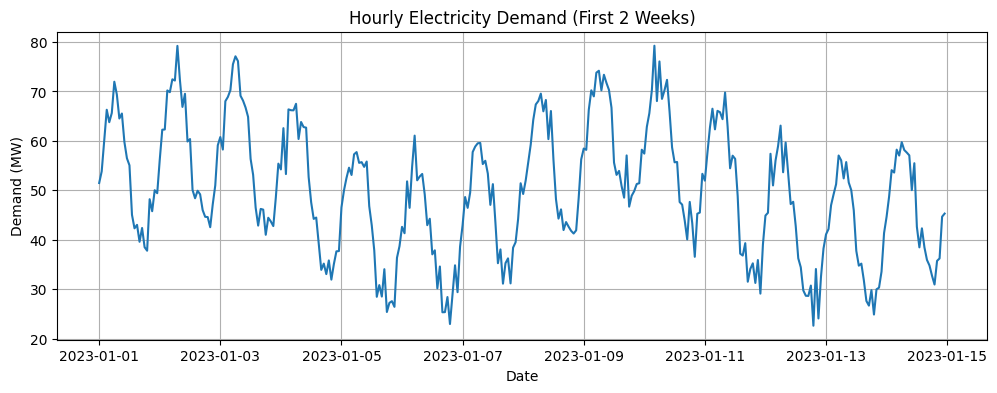

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate synthetic hourly electricity demand for 1 year (365 days * 24 hours)
np.random.seed(42)
time = np.arange(0, 365 * 24)
# Base demand + daily seasonality + weekly seasonality + noise
base_demand = 50
daily_pattern = 15 * np.sin(2 * np.pi * time / 24)
weekly_pattern = 10 * np.sin(2 * np.pi * time / (24 * 7))
noise = np.random.normal(0, 3, len(time))

demand = base_demand + daily_pattern + weekly_pattern + noise

# Create Pandas DataFrame
dates = pd.date_range(start="2023-01-01", periods=len(time), freq="H")
df = pd.DataFrame(data={'Demand': demand}, index=dates)

# Handle missing values if any (forward fill)
df = df.ffill()

# Scale the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
df['Scaled_Demand'] = scaler.fit_transform(df[['Demand']])

# Plot the first 2 weeks to visualize
plt.figure(figsize=(12, 4))
plt.plot(df['Demand'].iloc[:24*14])
plt.title('Hourly Electricity Demand (First 2 Weeks)')
plt.xlabel('Date')
plt.ylabel('Demand (MW)')
plt.grid(True)
plt.show()

# Task 2 & 3: Create Sliding Windows & Chronological Split
We convert the sequential time-series into supervised data structures with sliding windows of size 24 (past 24 hours to predict the next hour) and split chronologically.

In [4]:
def create_sliding_windows(data, window_size=24):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i + window_size])
        y.append(data[i + window_size])
    return np.array(X), np.array(y)

window_size = 24
series = df['Scaled_Demand'].values

X, y = create_sliding_windows(series, window_size)

# Reshape X to fit [samples, time steps, features]
X = X.reshape((X.shape[0], X.shape[1], 1))

# Chronological split: 80% train, 20% test
split_idx = int(len(X) * 0.8)

X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

X_train shape: (6988, 24, 1), y_train shape: (6988,)
X_test shape: (1748, 24, 1), y_test shape: (1748,)


# Task 4 & 5: Build, Train, Predict, and Evaluate the SimpleRNN

In [6]:
# Build the SimpleRNN architecture
model = Sequential([
    SimpleRNN(32, activation='tanh', input_shape=(window_size, 1)),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# Train the network
history = model.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.1, verbose=1)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0160 - val_loss: 0.0051
Epoch 2/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0046 - val_loss: 0.0048
Epoch 3/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0040 - val_loss: 0.0040
Epoch 4/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0037 - val_loss: 0.0039
Epoch 5/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0036 - val_loss: 0.0036
Epoch 6/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0034 - val_loss: 0.0035
Epoch 7/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0033 - val_loss: 0.0035
Epoch 8/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0032 - val_loss: 0.0035
Epoch 9/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0032 - val_loss: 0.0035
Epoch 10/10
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0032 - val_loss: 0.0033


55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Validation Mean Absolute Error (MAE): 3.0272 MW
Validation Root Mean Squared Error (RMSE): 3.7769 MW


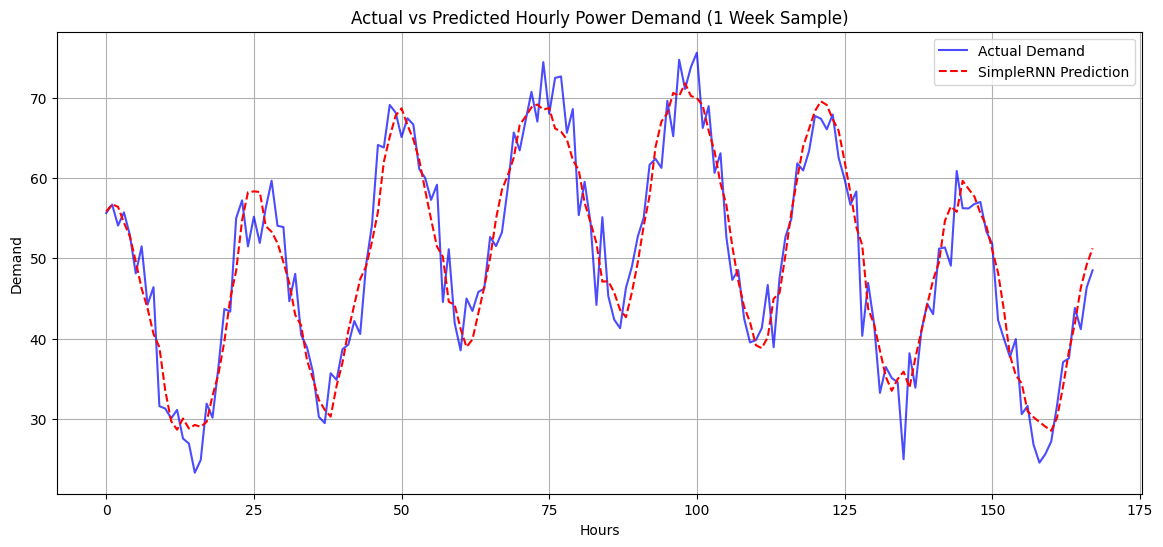

In [5]:
# Predict next values
predictions_scaled = model.predict(X_test)

# Inverse scaling to fetch real values
predictions = scaler.inverse_transform(predictions_scaled)
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1))

# Evaluate accuracy metrics
mae = mean_absolute_error(y_test_actual, predictions)
rmse = np.sqrt(mean_squared_error(y_test_actual, predictions))

print(f"Validation Mean Absolute Error (MAE): {mae:.4f} MW")
print(f"Validation Root Mean Squared Error (RMSE): {rmse:.4f} MW")

# Plot actual vs predicted
plt.figure(figsize=(14, 6))
plt.plot(y_test_actual[:168], label='Actual Demand', color='blue', alpha=0.7)
plt.plot(predictions[:168], label='SimpleRNN Prediction', color='red', linestyle='--')
plt.title('Actual vs Predicted Hourly Power Demand (1 Week Sample)')
plt.xlabel('Hours')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)
plt.show()